In [ ]:
import cv2 as cv
import numpy as np
from PyQt5.QtWidgets import *
import sys
import winsound

class TrafficWeak(QMainWindow):
    def __init__(self):
        super().__init__()
        self.setWindowTitle('교통약자 보호')
        self.setGeometry(200,200,700,200)
       
        signButton=QPushButton('표지판 등록',self)
        roadButton=QPushButton('도로 영상 불러옴',self)
        recognitionButton=QPushButton('인식',self)
        quitButton=QPushButton('나가기',self)
        self.label=QLabel('환영합니다!',self)
        
        signButton.setGeometry(10,10,100,30)
        roadButton.setGeometry(110,10,100,30)
        recognitionButton.setGeometry(210,10,100,30)
        quitButton.setGeometry(510,10,100,30)
        self.label.setGeometry(10,40,600,170)
        
        signButton.clicked.connect(self.signFunction)
        roadButton.clicked.connect(self.roadFunction) 
        recognitionButton.clicked.connect(self.recognitionFunction)        
        quitButton.clicked.connect(self.quitFunction)

        self.signFiles=[['child.png','어린이'],['elder.png','노인'],['disabled.png','장애인']]	# 표지판 모델 영상
        self.signImgs=[]				# 표지판 모델 영상 저장
        
    def signFunction(self):
        self.label.clear()
        self.label.setText('교통약자 번호판을 등록합니다.')
        
        for fname,_ in self.signFiles:
            self.signImgs.append(cv.imread(fname))
            cv.imshow(fname,self.signImgs[-1])        

    def roadFunction(self):
        if self.signImgs==[]: 
            self.label.setText('먼저 번호판을 등록하세요.')
        else:
            fname=QFileDialog.getOpenFileName(self,'파일 읽기','./')
            self.roadImg=cv.imread(fname[0])
            if self.roadImg is None: sys.exit('파일을 찾을 수 없습니다.')  
    
            cv.imshow('Road scene',self.roadImg)  
        
    def recognitionFunction(self):
        if self.roadImg is None: 
            self.label.setText('먼저 도로 영상을 입력하세요.')
        else:
            sift=cv.SIFT_create()
        
            KD=[] # 여러 표지판 영상의 키포인트와 기술자 저장
            for img in self.signImgs: 
                gray=cv.cvtColor(img,cv.COLOR_BGR2GRAY)
                KD.append(sift.detectAndCompute(gray,None))
                
            grayRoad=cv.cvtColor(self.roadImg,cv.COLOR_BGR2GRAY) # 명암으로 변환
            road_kp,road_des=sift.detectAndCompute(grayRoad,None) # 키포인트와 기술자 추출
                
            matcher=cv.DescriptorMatcher_create(cv.DescriptorMatcher_FLANNBASED)
            GM=[]			# 여러 표지판 영상의 good match를 저장
            for sign_kp,sign_des in KD:
                knn_match=matcher.knnMatch(sign_des,road_des,2)
                T=0.7
                good_match=[]
                for nearest1,nearest2 in knn_match:
                    if (nearest1.distance/nearest2.distance)<T:
                        good_match.append(nearest1)
                GM.append(good_match)        
            
            best=GM.index(max(GM,key=len)) # 매칭 쌍 개수가 최대인 번호판 찾기
            
            if len(GM[best])<4:	# 최선의 번호판이 매칭 쌍 4개 미만이면 실패
                self.label.setText('표지판이 없습니다.')  
            else:			# 성공(호모그래피 찾아 영상에 표시)
                sign_kp=KD[best][0]
                good_match=GM[best]
            
                points1=np.float32([sign_kp[gm.queryIdx].pt for gm in good_match])
                points2=np.float32([road_kp[gm.trainIdx].pt for gm in good_match])
                
                H,_=cv.findHomography(points1,points2,cv.RANSAC)
                
                h1,w1=self.signImgs[best].shape[0],self.signImgs[best].shape[1] # 번호판 영상의 크기
                h2,w2=self.roadImg.shape[0],self.roadImg.shape[1] # 도로 영상의 크기
                
                box1=np.float32([[0,0],[0,h1-1],[w1-1,h1-1],[w1-1,0]]).reshape(4,1,2)
                box2=cv.perspectiveTransform(box1,H)
                
                self.roadImg=cv.polylines(self.roadImg,[np.int32(box2)],True,(0,255,0),4)
                
                img_match=np.empty((max(h1,h2),w1+w2,3),dtype=np.uint8)
                cv.drawMatches(self.signImgs[best],sign_kp,self.roadImg,road_kp,good_match,img_match,flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
                cv.imshow('Matches and Homography',img_match)
                
                self.label.setText(self.signFiles[best][1]+' 보호구역입니다. 30km로 서행하세요.')                 
                winsound.Beep(3000,500)         
                      
    def quitFunction(self):
        cv.destroyAllWindows()        
        self.close()
                
app=QApplication(sys.argv) 
win=TrafficWeak() 
win.show()
app.exec_()

In [ ]:
import cv2 as cv
import numpy as np
from PyQt5.QtWidgets import *
import sys
import winsound

# 한글 경로를 포함한 이미지 파일을 읽기 위한 유틸리티 함수
def imread_korean(filename, flags=cv.IMREAD_COLOR):
    try:
        # 파일 데이터를 np.uint8 배열로 읽어와 imdecode로 바이트 해석
        n = np.fromfile(filename, np.uint8)
        img = cv.imdecode(n, flags)
        return img
    except Exception as e:
        print(f"이미지 로드 실패: {e}")
        return None

class TrafficWeak(QMainWindow):
    def __init__(self):
        super().__init__()
        self.setWindowTitle('교통약자 보호')
        self.setGeometry(200, 200, 700, 200)

        #button 상자 객체 생성
        signButton = QPushButton('표지판 등록', self)
        roadButton = QPushButton('도로 영상 불러옴', self)
        recognitionButton = QPushButton('인식', self)
        quitButton = QPushButton('나가기', self)
        self.label = QLabel('환영합니다!', self)

        #button 객체 위치와 크기 지정
        signButton.setGeometry(10, 10, 100, 30)
        roadButton.setGeometry(110, 10, 100, 30)
        recognitionButton.setGeometry(210, 10, 100, 30)
        quitButton.setGeometry(510, 10, 100, 30)
        self.label.setGeometry(10, 40, 600, 170)

        #버튼 클릭시 연결된 함수 실행
        signButton.clicked.connect(self.signFunction)
        roadButton.clicked.connect(self.roadFunction) 
        recognitionButton.clicked.connect(self.recognitionFunction)        
        quitButton.clicked.connect(self.quitFunction)

        #이미지 파일들 경로 저장(어린이,노인,장애인 등)
        self.signFiles = [['./ch6/child.png', '어린이'], ['./ch6/elder.png', '노인'], ['./ch6/disabled.png', '장애인']]  # 표지판 모델 영상
        self.signImgs = []                # 표지판 모델 영상 저장
        self.roadImg = None               # 도로 영상 초기화
        
    def signFunction(self):
        self.label.clear()
        self.label.setText('교통약자 번호판을 등록합니다.')
        self.signImgs.clear() # 기존 등록된 이미지 초기화
        
        for fname, _ in self.signFiles:
            # cv.imread 대신 imread_korean 사용
            img = imread_korean(fname)
            if img is not None:
                self.signImgs.append(img)
                cv.imshow(fname, self.signImgs[-1])
            else:
                self.label.setText(f'{fname} 이미지를 읽을 수 없습니다.')

    def roadFunction(self):
        if not self.signImgs: 
            self.label.setText('먼저 번호판을 등록하세요.')
        else:
            fname, _ = QFileDialog.getOpenFileName(self, '파일 읽기', './')
            if fname: # 사용자가 파일을 선택한 경우
                # cv.imread 대신 imread_korean 사용
                self.roadImg = imread_korean(fname)
                if self.roadImg is None: 
                    self.label.setText('파일을 읽을 수 없습니다. 경로를 확인해주세요.')
                    return
                cv.imshow('Road scene', self.roadImg)
        
    def recognitionFunction(self):
        if self.roadImg is None: 
            self.label.setText('먼저 도로 영상을 입력하세요.')
            return

        #sift로 특징점 찾기    
        sift = cv.SIFT_create()
    
        KD = [] # 여러 표지판 영상의 키포인트와 기술자 저장
        for img in self.signImgs: 
            gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
            KD.append(sift.detectAndCompute(gray, None))
            
        grayRoad = cv.cvtColor(self.roadImg, cv.COLOR_BGR2GRAY) # 명암으로 변환
        road_kp, road_des = sift.detectAndCompute(grayRoad, None) # 키포인트와 기술자 추출

        #flann으로 첫번째 특징점과 2번째 특징점 비교해서 차이가 0.7이상 나지 않으면 버림    
        matcher = cv.DescriptorMatcher_create(cv.DescriptorMatcher_FLANNBASED)
        GM = []           # 여러 표지판 영상의 good match를 저장
        for sign_kp, sign_des in KD:
            knn_match = matcher.knnMatch(sign_des, road_des, 2)
            T = 0.7
            good_match = []
            for nearest1, nearest2 in knn_match:
                if (nearest1.distance / nearest2.distance) < T:
                    good_match.append(nearest1)
            #유의미한 차이가 있으면 특징점에 저장
            GM.append(good_match)        
        
        best = GM.index(max(GM, key=len)) # 매칭 쌍 개수가 최대인 번호판 찾기
        
        if len(GM[best]) < 4: # 최선의 번호판이 매칭 쌍 4개 미만이면 실패
            self.label.setText('표지판이 없습니다.')  
        else:           # 성공(호모그래피 찾아 영상에 표시)
            sign_kp = KD[best][0]
            good_match = GM[best]
        
            points1 = np.float32([sign_kp[gm.queryIdx].pt for gm in good_match])
            points2 = np.float32([road_kp[gm.trainIdx].pt for gm in good_match])

            #맨처음에 찾은 특징점들과 최적의 특징점들을 비교해서 잘못된 매칭 오차를 골라내기 위해 란삭으로 행렬계산
            H, _ = cv.findHomography(points1, points2, cv.RANSAC)
            
            h1, w1 = self.signImgs[best].shape[0], self.signImgs[best].shape[1] # 번호판 영상의 크기
            h2, w2 = self.roadImg.shape[0], self.roadImg.shape[1] # 도로 영상의 크기
            
            #원본 표지판 위치 설정
            box1 = np.float32([[0, 0], [0, h1 - 1], [w1 - 1, h1 - 1], [w1 - 1, 0]]).reshape(4, 1, 2)
            #란삭으로 계산한 값을 반영해서 박스 위치 저장
            box2 = cv.perspectiveTransform(box1, H)
            
            #위에 box2 초록색 박스로 그리기
            self.roadImg = cv.polylines(self.roadImg, [np.int32(box2)], True, (0, 255, 0), 4)

            #두개의 이미지를 합쳐서 그릴 빈 도화지 만들기
            img_match = np.empty((max(h1, h2), w1 + w2, 3), dtype=np.uint8)
            #특징점을 잇는 선 그리기
            cv.drawMatches(self.signImgs[best], sign_kp, self.roadImg, road_kp, good_match, img_match, flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
            cv.imshow('Matches and Homography', img_match)
            
            self.label.setText(self.signFiles[best][1] + ' 보호구역입니다. 30km로 서행하세요.')                
            winsound.Beep(3000, 500)         

    #박스 종료
    def quitFunction(self):
        cv.destroyAllWindows()        
        self.close()
#main 함수 실행하고 앱 실행하고 윈도우 실행하고 앱 실행하기
if __name__ == '__main__':
    app = QApplication(sys.argv) 
    win = TrafficWeak() 
    win.show()
    app.exec_()

In [ ]:
from PyQt5.QtWidgets import *
import cv2 as cv
import numpy as np
import winsound
import sys
   
class Panorama(QMainWindow) :
    def __init__(self) :
        super().__init__()
        self.setWindowTitle('파노라마 영상')
        self.setGeometry(200,200,700,200)
        
        collectButton=QPushButton('영상 수집',self)
        self.showButton=QPushButton('영상 보기',self) 
        self.stitchButton=QPushButton('봉합',self) 
        self.saveButton=QPushButton('저장',self)
        quitButton=QPushButton('나가기',self)
        self.label=QLabel('환영합니다!',self)
        
        collectButton.setGeometry(10,25,100,30)
        self.showButton.setGeometry(110,25,100,30) 
        self.stitchButton.setGeometry(210,25,100,30) 
        self.saveButton.setGeometry(310,25,100,30)
        quitButton.setGeometry(450,25,100,30) 
        self.label.setGeometry(10,70,600,170)

        self.showButton.setEnabled(False) 
        self.stitchButton.setEnabled(False) 
        self.saveButton.setEnabled(False)
        
        collectButton.clicked.connect(self.collectFunction)
        self.showButton.clicked.connect(self.showFunction)       
        self.stitchButton.clicked.connect(self.stitchFunction) 
        self.saveButton.clicked.connect(self.saveFunction)   
        quitButton.clicked.connect(self.quitFunction)        

    def collectFunction(self):
        self.showButton.setEnabled(False) 
        self.stitchButton.setEnabled(False) 
        self.saveButton.setEnabled(False)
        self.label.setText('c를 여러 번 눌러 수집하고 끝나면 q를 눌러 비디오를 끕니다.')
        
        self.cap=cv.VideoCapture(0,cv.CAP_DSHOW) 
        if not self.cap.isOpened(): sys.exit('카메라 연결 실패')
        
        self.imgs=[]   
        while True:
            ret,frame=self.cap.read()  
            if not ret: break
            
            cv.imshow('video display', frame)
            
            key=cv.waitKey(1) 
            if key==ord('c'):            
                self.imgs.append(frame)	# 영상 저장
            elif key==ord('q'):
                self.cap.release() 
                cv.destroyWindow('video display')                
                break 
        
        if len(self.imgs)>=2:		# 수집한 영상이 2장 이상이면
            self.showButton.setEnabled(True) 
            self.stitchButton.setEnabled(True) 
            self.saveButton.setEnabled(True)        
                    
    def showFunction(self):
        self.label.setText('수집된 영상은 '+str(len(self.imgs))+'장 입니다.')
        stack=cv.resize(self.imgs[0],dsize=(0,0),fx=0.25,fy=0.25)
        for i in range(1,len(self.imgs)):
            stack=np.hstack((stack,cv.resize(self.imgs[i],dsize=(0,0),fx=0.25,fy=0.25))) 
        cv.imshow('Image collection',stack)        
        
    def stitchFunction(self):
        stitcher=cv.Stitcher_create()
        status,self.img_stitched=stitcher.stitch(self.imgs)
        if status==cv.STITCHER_OK:
            cv.imshow('Image stitched panorama',self.img_stitched)     
        else:
            winsound.Beep(3000,500)            
            self.label.setText('파노라마 제작에 실패했습니다. 다시 시도하세요.')    
            
    def saveFunction(self):
        fname=QFileDialog.getSaveFileName(self,'파일 저장','./')
        cv.imwrite(fname[0],self.img_stitched)
        
    def quitFunction(self): 
        self.cap.release() 
        cv.destroyAllWindows()  
        self.close()

app=QApplication(sys.argv) 
win=Panorama() 
win.show()
app.exec_()

In [1]:
from PyQt5.QtWidgets import *
import cv2 as cv
import numpy as np
import winsound
import sys
import os

# 한글 경로를 포함하여 이미지 파일로 저장하기 위한 유틸리티 함수
def imwrite_korean(filename, img, params=None):
    try:
        # 파일 확장자 추출 (.png, .jpg 등)
        ext = os.path.splitext(filename)[1]
        if not ext:
            ext = '.png'  # 확장자가 없으면 기본적으로 .png 사용
            filename += ext
            
        # 이미지를 인코딩하여 메모리 버퍼로 변환 후 파일로 작성
        result, encoded_img = cv.imencode(ext, img, params)
        if result:
            with open(filename, mode='wb') as f:
                encoded_img.tofile(f)
            return True
        return False
    except Exception as e:
        print(f"이미지 저장 실패: {e}")
        return False

class Panorama(QMainWindow):
    def __init__(self):
        super().__init__()
        self.setWindowTitle('파노라마 영상')
        self.setGeometry(200, 200, 700, 200)
        
        collectButton = QPushButton('영상 수집', self)
        self.showButton = QPushButton('영상 보기', self) 
        self.stitchButton = QPushButton('봉합', self) 
        self.saveButton = QPushButton('저장', self)
        quitButton = QPushButton('나가기', self)
        self.label = QLabel('환영합니다!', self)
        
        collectButton.setGeometry(10, 25, 100, 30)
        self.showButton.setGeometry(110, 25, 100, 30) 
        self.stitchButton.setGeometry(210, 25, 100, 30) 
        self.saveButton.setGeometry(310, 25, 100, 30)
        quitButton.setGeometry(450, 25, 100, 30) 
        self.label.setGeometry(10, 70, 600, 170)

        self.showButton.setEnabled(False) 
        self.stitchButton.setEnabled(False) 
        self.saveButton.setEnabled(False)
        
        collectButton.clicked.connect(self.collectFunction)
        self.showButton.clicked.connect(self.showFunction)       
        self.stitchButton.clicked.connect(self.stitchFunction) 
        self.saveButton.clicked.connect(self.saveFunction)   
        quitButton.clicked.connect(self.quitFunction)        
        
        self.cap = None
        self.imgs = []
        self.img_stitched = None

    def collectFunction(self):
        self.showButton.setEnabled(False) 
        self.stitchButton.setEnabled(False) 
        self.saveButton.setEnabled(False)
        self.label.setText('c를 여러 번 눌러 수집하고 끝나면 q를 눌러 비디오를 끕니다.')
        
        self.cap = cv.VideoCapture(0, cv.CAP_DSHOW) 
        if not self.cap.isOpened(): 
            self.label.setText('카메라 연결 실패')
            return
        
        self.imgs = []   
        while True:
            ret, frame = self.cap.read()  
            if not ret: break
            
            cv.imshow('video display', frame)
            
            key = cv.waitKey(1) 
            if key == ord('c'):            
                self.imgs.append(frame) # 영상 저장
            elif key == ord('q'):
                self.cap.release() 
                cv.destroyWindow('video display')                
                break 
        
        if len(self.imgs) >= 2:       # 수집한 영상이 2장 이상이면
            self.showButton.setEnabled(True) 
            self.stitchButton.setEnabled(True) 
            self.saveButton.setEnabled(True)        
                    
    def showFunction(self):
        self.label.setText('수집된 영상은 ' + str(len(self.imgs)) + '장 입니다.')
        stack = cv.resize(self.imgs[0], dsize=(0, 0), fx=0.25, fy=0.25)
        for i in range(1, len(self.imgs)):
            stack = np.hstack((stack, cv.resize(self.imgs[i], dsize=(0, 0), fx=0.25, fy=0.25))) 
        cv.imshow('Image collection', stack)        
        
    def stitchFunction(self):
        stitcher = cv.Stitcher_create()
        status, self.img_stitched = stitcher.stitch(self.imgs)
        if status == cv.STITCHER_OK:
            cv.imshow('Image stitched panorama', self.img_stitched)     
        else:
            winsound.Beep(3000, 500)            
            self.label.sㅊetText('파노라마 제작에 실패했습니다. 다시 시도하세요.')    
            
    def saveFunction(self):
        if self.img_stitched is None:
            self.label.setText('저장할 파노라마 영상이 없습니다.')
            return
            
        fname, _ = QFileDialog.getSaveFileName(self, '파일 저장', './', 'Images (*.png *.jpg *.jpeg)')
        if fname:
            # cv.imwrite 대신 한글 경로 지원 함수 사용
            if imwrite_korean(fname, self.img_stitched):
                self.label.setText('성공적으로 저장되었습니다.')
            else:
                self.label.setText('파일 저장에 실패했습니다.')
        
    def quitFunction(self): 
        if self.cap is not None and self.cap.isOpened():
            self.cap.release() 
        cv.destroyAllWindows()  
        self.close()

if __name__ == '__main__':
    app = QApplication(sys.argv) 
    win = Panorama() 
    win.show()
    app.exec_()

In [1]:
import cv2 as cv
import numpy as np
from PyQt5.QtWidgets import *
import sys    
    
class SpecialEffect(QMainWindow):
    def __init__(self):
        super().__init__()
        self.setWindowTitle('사진 특수 효과')
        self.setGeometry(200,200,800,200)
       
        pictureButton=QPushButton('사진 읽기',self)
        embossButton=QPushButton('엠보싱',self)
        cartoonButton=QPushButton('카툰',self)
        sketchButton=QPushButton('연필 스케치',self)
        oilButton=QPushButton('유화',self)
        saveButton=QPushButton('저장하기',self) 
        self.pickCombo=QComboBox(self)     
        self.pickCombo.addItems(['엠보싱','카툰','연필 스케치(명암)','연필 스케치(컬러)','유화'])
        quitButton=QPushButton('나가기',self)        
        self.label=QLabel('환영합니다!',self)
        
        pictureButton.setGeometry(10,10,100,30)
        embossButton.setGeometry(110,10,100,30)
        cartoonButton.setGeometry(210,10,100,30)
        sketchButton.setGeometry(310,10,100,30)
        oilButton.setGeometry(410,10,100,30)  
        saveButton.setGeometry(510,10,100,30)
        self.pickCombo.setGeometry(510,40,110,30)                  
        quitButton.setGeometry(620,10,100,30)
        self.label.setGeometry(10,40,500,170)
        
        pictureButton.clicked.connect(self.pictureOpenFunction)
        embossButton.clicked.connect(self.embossFunction) 
        cartoonButton.clicked.connect(self.cartoonFunction)
        sketchButton.clicked.connect(self.sketchFunction)
        oilButton.clicked.connect(self.oilFunction) 
        saveButton.clicked.connect(self.saveFunction)    
        quitButton.clicked.connect(self.quitFunction)

    def pictureOpenFunction(self):
        fname=QFileDialog.getOpenFileName(self,'사진 읽기','./')
        self.img=cv.imread(fname[0])    
        if self.img is None: sys.exit('파일을 찾을 수 없습니다.')  
        
        cv.imshow('Painting',self.img)         

    def embossFunction(self):
        femboss=np.array([[-1.0, 0.0, 0.0],[0.0, 0.0, 0.0],[0.0, 0.0, 1.0]])
        
        gray=cv.cvtColor(self.img,cv.COLOR_BGR2GRAY)    
        gray16=np.int16(gray)
        self.emboss=np.uint8(np.clip(cv.filter2D(gray16,-1,femboss)+128,0,255))
        
        cv.imshow('Emboss',self.emboss)
    
    def cartoonFunction(self):
        self.cartoon=cv.stylization(self.img,sigma_s=60,sigma_r=0.45)
        cv.imshow('Cartoon',self.cartoon) 
    
    def sketchFunction(self):
        self.sketch_gray,self.sketch_color=cv.pencilSketch(self.img,sigma_s=60,sigma_r=0.07,shade_factor=0.02)
        cv.imshow('Pencil sketch(gray)',self.sketch_gray)
        cv.imshow('Pencil sketch(color)',self.sketch_color)

    def oilFunction(self):
        self.oil=cv.xphoto.oilPainting(self.img,10,1,cv.COLOR_BGR2Lab)
        cv.imshow('Oil painting',self.oil) 
                           
    def saveFunction(self):      
        fname=QFileDialog.getSaveFileName(self,'파일 저장','./')
        
        i=self.pickCombo.currentIndex()
        if i==0: cv.imwrite(fname[0],self.emboss)
        elif i==1: cv.imwrite(fname[0],self.cartoon)
        elif i==2: cv.imwrite(fname[0],self.sketch_gray)
        elif i==3: cv.imwrite(fname[0],self.sketch_color)
        elif i==4: cv.imwrite(fname[0],self.oil)
                        
    def quitFunction(self):
        cv.destroyAllWindows()        
        self.close()
                
app=QApplication(sys.argv) 
win=SpecialEffect() 
win.show()
app.exec_()

: 

In [1]:
import cv2 as cv
import numpy as np
from PyQt5.QtWidgets import *
import sys 
import os

# 1. 한글 경로 읽기 지원 함수
def imread_korean(filename, flags=cv.IMREAD_COLOR):
    try:
        n = np.fromfile(filename, np.uint8)
        img = cv.imdecode(n, flags)
        return img
    except Exception as e:
        print(f"이미지 로드 실패: {e}")
        return None

# 2. 한글 경로 저장 지원 함수
def imwrite_korean(filename, img, params=None):
    try:
        ext = os.path.splitext(filename)[1]
        if not ext:
            ext = '.png'  # 확장자 지정이 안 되어 있으면 기본 .png
            filename += ext
            
        result, encoded_img = cv.imencode(ext, img, params)
        if result:
            with open(filename, mode='wb') as f:
                encoded_img.tofile(f)
            return True
        return False
    except Exception as e:
        print(f"이미지 저장 실패: {e}")
        return False

class SpecialEffect(QMainWindow):
    def __init__(self):
        super().__init__()
        self.setWindowTitle('사진 특수 효과')
        self.setGeometry(200, 200, 800, 200)
        
        # 변수 초기화
        self.img = None
        self.emboss = None
        self.cartoon = None
        self.sketch_gray = None
        self.sketch_color = None
        self.oil = None
       
        pictureButton = QPushButton('사진 읽기', self)
        embossButton = QPushButton('엠보싱', self)
        cartoonButton = QPushButton('카툰', self)
        sketchButton = QPushButton('연필 스케치', self)
        oilButton = QPushButton('유화', self)
        saveButton = QPushButton('저장하기', self) 
        self.pickCombo = QComboBox(self)     
        self.pickCombo.addItems(['엠보싱', '카툰', '연필 스케치(명암)', '연필 스케치(컬러)', '유화'])
        quitButton = QPushButton('나가기', self)        
        self.label = QLabel('환영합니다!', self)
        
        pictureButton.setGeometry(10, 10, 100, 30)
        embossButton.setGeometry(110, 10, 100, 30)
        cartoonButton.setGeometry(210, 10, 100, 30)
        sketchButton.setGeometry(310, 10, 100, 30)
        oilButton.setGeometry(410, 10, 100, 30)  
        saveButton.setGeometry(510, 10, 100, 30)
        self.pickCombo.setGeometry(510, 40, 130, 30)                  
        quitButton.setGeometry(650, 10, 100, 30)
        self.label.setGeometry(10, 40, 500, 170)
        
        pictureButton.clicked.connect(self.pictureOpenFunction)
        embossButton.clicked.connect(self.embossFunction) 
        cartoonButton.clicked.connect(self.cartoonFunction)
        sketchButton.clicked.connect(self.sketchFunction)
        oilButton.clicked.connect(self.oilFunction) 
        saveButton.clicked.connect(self.saveFunction)    
        quitButton.clicked.connect(self.quitFunction)

    def pictureOpenFunction(self):
        fname, _ = QFileDialog.getOpenFileName(self, '사진 읽기', './')
        if fname:
            # cv.imread 대신 한글 읽기 함수 사용
            self.img = imread_korean(fname)    
            if self.img is None: 
                self.label.setText('파일을 읽을 수 없습니다.')
                return
            
            self.label.setText('사진을 성공적으로 불러왔습니다.')
            cv.imshow('Painting', self.img)         

    def embossFunction(self):
        if self.img is None: return
        femboss = np.array([[-1.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 1.0]])
        
        gray = cv.cvtColor(self.img, cv.COLOR_BGR2GRAY)    
        gray16 = np.int16(gray)
        self.emboss = np.uint8(np.clip(cv.filter2D(gray16, -1, femboss) + 128, 0, 255))
        
        cv.imshow('Emboss', self.emboss)
    
    def cartoonFunction(self):
        if self.img is None: return
        self.cartoon = cv.stylization(self.img, sigma_s=60, sigma_r=0.45)
        cv.imshow('Cartoon', self.cartoon) 
    
    def sketchFunction(self):
        if self.img is None: return
        self.sketch_gray, self.sketch_color = cv.pencilSketch(self.img, sigma_s=60, sigma_r=0.07, shade_factor=0.02)
        cv.imshow('Pencil sketch(gray)', self.sketch_gray)
        cv.imshow('Pencil sketch(color)', self.sketch_color)

    def oilFunction(self):
        if self.img is None: return
        self.oil = cv.xphoto.oilPainting(self.img, 10, 1, cv.COLOR_BGR2Lab)
        cv.imshow('Oil painting', self.oil) 
                            
    def saveFunction(self):      
        fname, _ = QFileDialog.getSaveFileName(self, '파일 저장', './', 'Images (*.png *.jpg *.jpeg)')
        if not fname:
            return

        i = self.pickCombo.currentIndex()
        target_img = None

        if i == 0: target_img = self.emboss
        elif i == 1: target_img = self.cartoon
        elif i == 2: target_img = self.sketch_gray
        elif i == 3: target_img = self.sketch_color
        elif i == 4: target_img = self.oil

        if target_img is None:
            self.label.setText('해당 효과를 먼저 실행한 후 저장해주세요.')
            return

        # cv.imwrite 대신 한글 저장 함수 사용
        if imwrite_korean(fname, target_img):
            self.label.setText('성공적으로 저장되었습니다.')
        else:
            self.label.setText('저장에 실패했습니다.')
                        
    def quitFunction(self):
        cv.destroyAllWindows()        
        self.close()

if __name__ == '__main__':
    app = QApplication(sys.argv) 
    win = SpecialEffect() 
    win.show()
    app.exec_()

AttributeError: module 'cv2' has no attribute 'xphoto'

AttributeError: module 'cv2' has no attribute 'xphoto'

In [1]:
import cv2 as cv
import numpy as np
from PyQt5.QtWidgets import *
import sys 
import os

# 1. 한글 경로 읽기 지원 함수
def imread_korean(filename, flags=cv.IMREAD_COLOR):
    try:
        n = np.fromfile(filename, np.uint8)
        img = cv.imdecode(n, flags)
        return img
    except Exception as e:
        print(f"이미지 로드 실패: {e}")
        return None

# 2. 한글 경로 저장 지원 함수
def imwrite_korean(filename, img, params=None):
    try:
        ext = os.path.splitext(filename)[1]
        if not ext:
            ext = '.png'  # 확장자 지정이 안 되어 있으면 기본 .png
            filename += ext
            
        result, encoded_img = cv.imencode(ext, img, params)
        if result:
            with open(filename, mode='wb') as f:
                encoded_img.tofile(f)
            return True
        return False
    except Exception as e:
        print(f"이미지 저장 실패: {e}")
        return False

class SpecialEffect(QMainWindow):
    def __init__(self):
        super().__init__()
        self.setWindowTitle('사진 특수 효과')
        self.setGeometry(200, 200, 800, 200)
        
        # 변수 초기화
        self.img = None
        self.emboss = None
        self.cartoon = None
        self.sketch_gray = None
        self.sketch_color = None
        self.oil = None
       
        pictureButton = QPushButton('사진 읽기', self)
        embossButton = QPushButton('엠보싱', self)
        cartoonButton = QPushButton('카툰', self)
        sketchButton = QPushButton('연필 스케치', self)
        oilButton = QPushButton('유화', self)
        saveButton = QPushButton('저장하기', self) 
        self.pickCombo = QComboBox(self)     
        self.pickCombo.addItems(['엠보싱', '카툰', '연필 스케치(명암)', '연필 스케치(컬러)', '유화'])
        quitButton = QPushButton('나가기', self)        
        self.label = QLabel('환영합니다!', self)
        
        pictureButton.setGeometry(10, 10, 100, 30)
        embossButton.setGeometry(110, 10, 100, 30)
        cartoonButton.setGeometry(210, 10, 100, 30)
        sketchButton.setGeometry(310, 10, 100, 30)
        oilButton.setGeometry(410, 10, 100, 30)  
        saveButton.setGeometry(510, 10, 100, 30)
        self.pickCombo.setGeometry(510, 40, 130, 30)                  
        quitButton.setGeometry(650, 10, 100, 30)
        self.label.setGeometry(10, 40, 500, 170)
        
        pictureButton.clicked.connect(self.pictureOpenFunction)
        embossButton.clicked.connect(self.embossFunction) 
        cartoonButton.clicked.connect(self.cartoonFunction)
        sketchButton.clicked.connect(self.sketchFunction)
        oilButton.clicked.connect(self.oilFunction) 
        saveButton.clicked.connect(self.saveFunction)    
        quitButton.clicked.connect(self.quitFunction)

    def pictureOpenFunction(self):
        fname, _ = QFileDialog.getOpenFileName(self, '사진 읽기', './')
        if fname:
            # cv.imread 대신 한글 읽기 함수 사용
            self.img = imread_korean(fname)    
            if self.img is None: 
                self.label.setText('파일을 읽을 수 없습니다.')
                return
            
            self.label.setText('사진을 성공적으로 불러왔습니다.')
            cv.imshow('Painting', self.img)         

    def embossFunction(self):
        if self.img is None: return
        femboss = np.array([[-1.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 1.0]])
        
        gray = cv.cvtColor(self.img, cv.COLOR_BGR2GRAY)    
        gray16 = np.int16(gray)
        self.emboss = np.uint8(np.clip(cv.filter2D(gray16, -1, femboss) + 128, 0, 255))
        
        cv.imshow('Emboss', self.emboss)
    
    def cartoonFunction(self):
        if self.img is None: return
        self.cartoon = cv.stylization(self.img, sigma_s=60, sigma_r=0.45)
        cv.imshow('Cartoon', self.cartoon) 
    
    def sketchFunction(self):
        if self.img is None: return
        self.sketch_gray, self.sketch_color = cv.pencilSketch(self.img, sigma_s=60, sigma_r=0.07, shade_factor=0.02)
        cv.imshow('Pencil sketch(gray)', self.sketch_gray)
        cv.imshow('Pencil sketch(color)', self.sketch_color)

    def oilFunction(self):
        if self.img is None: return
        self.oil = cv.xphoto.oilPainting(self.img, 10, 1, cv.COLOR_BGR2Lab)
        cv.imshow('Oil painting', self.oil) 
                            
    def saveFunction(self):      
        fname, _ = QFileDialog.getSaveFileName(self, '파일 저장', './', 'Images (*.png *.jpg *.jpeg)')
        if not fname:
            return

        i = self.pickCombo.currentIndex()
        target_img = None

        if i == 0: target_img = self.emboss
        elif i == 1: target_img = self.cartoon
        elif i == 2: target_img = self.sketch_gray
        elif i == 3: target_img = self.sketch_color
        elif i == 4: target_img = self.oil

        if target_img is None:
            self.label.setText('해당 효과를 먼저 실행한 후 저장해주세요.')
            return

        # cv.imwrite 대신 한글 저장 함수 사용
        if imwrite_korean(fname, target_img):
            self.label.setText('성공적으로 저장되었습니다.')
        else:
            self.label.setText('저장에 실패했습니다.')
                        
    def quitFunction(self):
        cv.destroyAllWindows()        
        self.close()

if __name__ == '__main__':
    app = QApplication(sys.argv) 
    win = SpecialEffect() 
    win.show()
    app.exec_()

AttributeError: module 'cv2' has no attribute 'xphoto'

In [1]:
pip install opencv-contrib-python

Note: you may need to restart the kernel to use updated packages.


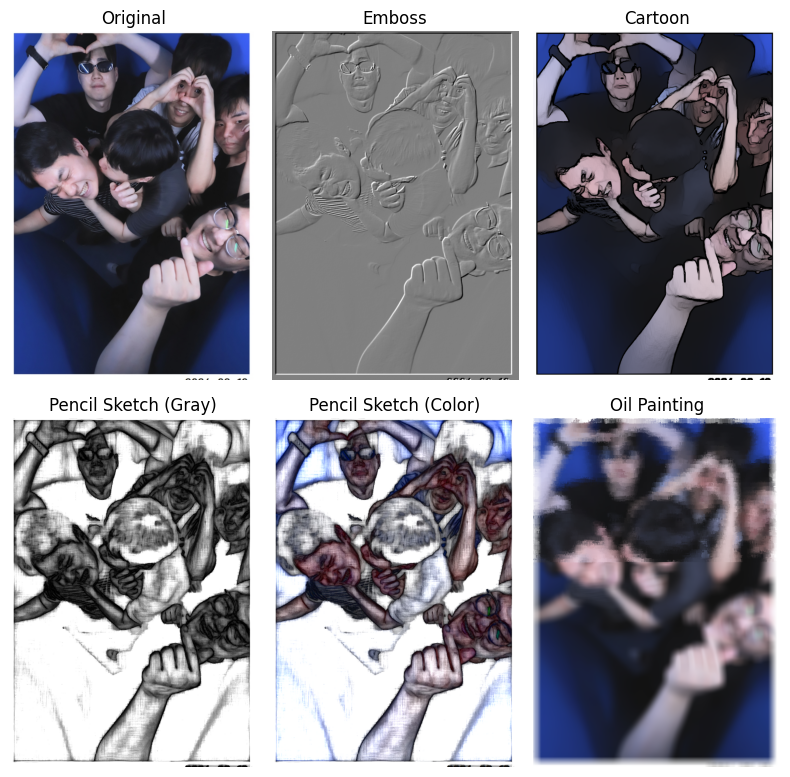

In [ ]:
import cv2 as cv
import numpy as np
from PyQt5.QtWidgets import *
import matplotlib.pyplot as plt
import sys 
import os

# 1. 한글 경로 읽기 지원 함수
def imread_korean(filename, flags=cv.IMREAD_COLOR):
    try:
        n = np.fromfile(filename, np.uint8)
        img = cv.imdecode(n, flags)
        return img
    except Exception as e:
        print(f"이미지 로드 실패: {e}")
        return None

# 2. 한글 경로 저장 지원 함수
def imwrite_korean(filename, img, params=None):
    try:
        ext = os.path.splitext(filename)[1]
        if not ext:
            ext = '.png'
            filename += ext
            
        result, encoded_img = cv.imencode(ext, img, params)
        if result:
            with open(filename, mode='wb') as f:
                encoded_img.tofile(f)
            return True
        return False
    except Exception as e:
        print(f"이미지 저장 실패: {e}")
        return False

class SpecialEffect(QMainWindow):
    def __init__(self):
        super().__init__()
        self.setWindowTitle('사진 특수 효과 (Matplotlib Subplot)')
        self.setGeometry(200, 200, 800, 200)
        
        # 변수 초기화
        self.img = None
        self.emboss = None
        self.cartoon = None
        self.sketch_gray = None
        self.sketch_color = None
        self.oil = None
       
        pictureButton = QPushButton('사진 읽기', self)
        applyAllButton = QPushButton('4개 한번에', self)
        saveButton = QPushButton('저장하기', self) 
        self.pickCombo = QComboBox(self)     
        self.pickCombo.addItems(['엠보싱', '카툰', '연필 스케치(명암)', '연필 스케치(컬러)', '유화'])
        quitButton = QPushButton('나가기', self)        
        self.label = QLabel('환영합니다! 사진을 먼저 읽어온 후 적용 버튼을 누르세요.', self)
        
        pictureButton.setGeometry(10, 10, 100, 30)
        applyAllButton.setGeometry(120, 10, 160, 30)
        saveButton.setGeometry(290, 10, 100, 30)
        self.pickCombo.setGeometry(400, 10, 140, 30)                  
        quitButton.setGeometry(550, 10, 100, 30)
        self.label.setGeometry(10, 50, 600, 120)

        #버튼 클릭시 함수에 연결
        pictureButton.clicked.connect(self.pictureOpenFunction)
        applyAllButton.clicked.connect(self.applyAndShowSubplot)
        saveButton.clicked.connect(self.saveFunction)    
        quitButton.clicked.connect(self.quitFunction)

    #파일을 열어서 사진을 로드한다
    def pictureOpenFunction(self):
        fname, _ = QFileDialog.getOpenFileName(self, '사진 읽기', './')
        if fname:
            self.img = imread_korean(fname)    
            if self.img is None: 
                self.label.setText('파일을 읽을 수 없습니다.')
                return
            
            self.label.setText('사진을 성공적으로 불러왔습니다. [특수효과 적용] 버튼을 누르세요.')

    #특수효과들 적용
    def applyAndShowSubplot(self):
        #self 이미지가 없을때
        if self.img is None:
            self.label.setText('먼저 사진을 불러와주세요.')
            return

        # 1. 엠보싱 처리
        femboss = np.array([[-1.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 1.0]])
        gray = cv.cvtColor(self.img, cv.COLOR_BGR2GRAY)    
        gray16 = np.int16(gray)
        # clip으로 255~0 범위 지정하고 filter2d 함수로 그레이 색의 엠보싱 커널 적용
        self.emboss = np.uint8(np.clip(cv.filter2D(gray16, -1, femboss) + 128, 0, 255))

        # 2. 카툰 처리
        self.cartoon = cv.stylization(self.img, sigma_s=60, sigma_r=0.45)

        # 3. 연필 스케치 처리 (명암, 컬러)
        self.sketch_gray, self.sketch_color = cv.pencilSketch(self.img, sigma_s=60, sigma_r=0.07, shade_factor=0.02)

        # 4. 유화 처리 (contrib 미설치 시 에러 방지)
        try:
            self.oil = cv.xphoto.oilPainting(self.img, 10, 1, cv.COLOR_BGR2Lab)
        except AttributeError:
            # opencv-contrib-python이 없는 경우 블러 효과로 대체
            self.oil = cv.bilateralFilter(self.img, 9, 75, 75)
            self.label.setText('주의: opencv-contrib 미설치로 유화 대신 대체 필터가 적용되었습니다.')

        #위의 필터를 적용한 이미지들을 opencv를 활용해서 저장
        img_rgb = cv.cvtColor(self.img, cv.COLOR_BGR2RGB)
        cartoon_rgb = cv.cvtColor(self.cartoon, cv.COLOR_BGR2RGB)
        sketch_color_rgb = cv.cvtColor(self.sketch_color, cv.COLOR_BGR2RGB)
        oil_rgb = cv.cvtColor(self.oil, cv.COLOR_BGR2RGB)

        plt.figure(figsize=(8, 8))

        # 1) 원본
        plt.subplot(2, 3, 1)
        plt.imshow(img_rgb)
        plt.title('Original')
        plt.axis('off')

        # 2) 엠보싱
        plt.subplot(2, 3, 2)
        plt.imshow(self.emboss, cmap='gray')
        plt.title('Emboss')
        plt.axis('off')

        # 3) 카툰
        plt.subplot(2, 3, 3)
        plt.imshow(cartoon_rgb)
        plt.title('Cartoon')
        plt.axis('off')

        # 4) 스케치 명암
        plt.subplot(2, 3, 4)
        plt.imshow(self.sketch_gray, cmap='gray')
        plt.title('Pencil Sketch (Gray)')
        plt.axis('off')

        # 5) 스케치 컬러
        plt.subplot(2, 3, 5)
        plt.imshow(sketch_color_rgb)
        plt.title('Pencil Sketch (Color)')
        plt.axis('off')

        # 6) 유화
        plt.subplot(2, 3, 6)
        plt.imshow(oil_rgb)
        plt.title('Oil Painting')
        plt.axis('off')

        plt.tight_layout()
        plt.show()

    def saveFunction(self):      
        fname, _ = QFileDialog.getSaveFileName(self, '파일 저장', './', 'Images (*.png *.jpg *.jpeg)')
        if not fname:
            return

        i = self.pickCombo.currentIndex()
        target_img = None

        if i == 0: target_img = self.emboss
        elif i == 1: target_img = self.cartoon
        elif i == 2: target_img = self.sketch_gray
        elif i == 3: target_img = self.sketch_color
        elif i == 4: target_img = self.oil

        if target_img is None:
            self.label.setText('특수효과를 먼저 적용한 후 저장해주세요.')
            return

        if imwrite_korean(fname, target_img):
            self.label.setText('성공적으로 저장되었습니다.')
        else:
            self.label.setText('저장에 실패했습니다.')
                        
    def quitFunction(self):
        plt.close('all')
        cv.destroyAllWindows()        
        self.close()

if __name__ == '__main__':
    app = QApplication(sys.argv) 
    win = SpecialEffect() 
    win.show()
    app.exec_()

In [5]:
import cv2 as cv
import numpy as np
def ascii_art_filter(frame):
    # 화면을 대폭 축소 (글자가 들어갈 해상도 크기로 감소)
    small_gray = cv.resize(frame, (120, 90))
    small_gray = cv.cvtColor(small_gray, cv.COLOR_BGR2GRAY)
    
    # 사용할 텍스트 배열 (밝기에 따른 문자 매핑)
    ascii_chars = ["@", "#", "S", "%", "?", "*", "+", ";", ":", ",", "."]
    
    # 검은색 빈 화면 생성
    h, w = frame.shape[:2]
    ascii_frame = np.zeros((h, w, 3), dtype=np.uint8)
    
    # 격자 크기 계산
    cell_w, cell_h = w / 120, h / 90
    for y in range(90):
        for x in range(120):
            brightness = small_gray[y, x]
            char_idx = int((brightness / 255) * (len(ascii_chars) - 1))
            char = ascii_chars[char_idx]
            
            # 초록색 아스키 문자로 이미지 그리기 (해커 스크린 느낌)
            pos = (int(x * cell_w), int(y * cell_h) + int(cell_h))
            cv.putText(ascii_frame, char, pos, cv.FONT_HERSHEY_SIMPLEX, 0.3, (0, 255, 0), 1)
            
    return ascii_frame
def apply_effect(frame, effect_type):
    if effect_type == 1:
        # 1. 엠보싱 효과
        femboss = np.array([[-1.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 1.0]])
        gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
        gray16 = np.int16(gray)
        emboss = np.uint8(np.clip(cv.filter2D(gray16, -1, femboss) + 128, 0, 255))
        return cv.cvtColor(emboss, cv.COLOR_GRAY2BGR) # 채널 맞춤

    elif effect_type == 2:
        # 2. 카툰 효과
        return cv.stylization(frame, sigma_s=60, sigma_r=0.45)

    elif effect_type == 3:
        # 3. 연필 스케치 효과 (명암)
        sketch_gray, _ = cv.pencilSketch(frame, sigma_s=60, sigma_r=0.07, shade_factor=0.02)
        return cv.cvtColor(sketch_gray, cv.COLOR_GRAY2BGR)

    elif effect_type == 4:
        # 4. 연필 스케치 효과 (컬러)
        _, sketch_color = cv.pencilSketch(frame, sigma_s=60, sigma_r=0.07, shade_factor=0.02)
        return sketch_color

    elif effect_type == 5:
        # 5. 유화 효과
        try:
            return cv.xphoto.oilPainting(frame, 7, 1, cv.COLOR_BGR2Lab)
        except AttributeError:
            return cv.bilateralFilter(frame, 9, 75, 75)

    elif effect_type == 6:
        # 사이버펑크 네온~
        try:
            gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
            edges = cv.Canny(gray, 100, 200)
            neon_line = cv.cvtColor(edges, cv.COLOR_GRAY2BGR)
            
            # 네온 느낌 연출: 초록색/시안색 하이라이트 추가
            neon_colored = cv.bitwise_and(frame, neon_line)
            return cv.addWeighted(frame, 0.3, neon_colored, 0.7, 0)

        except Exception as e:
            # 그 외 예외 발생 시 대체 필터 반환
            print(f"사이버펑크 효과 오류: {e}")
            return cv.bilateralFilter(frame, 9, 75, 75)
    elif effect_type == 7:
        # 7. 아스키 아트 필터
        return ascii_art_filter(frame)

    return frame # 0번 또는 기본: 원본 출력

# 웹캠 연결
cap = cv.VideoCapture(0, cv.CAP_DSHOW)
current_effect = 0

print("숫자 키를 눌러 효과를 변경하세요:")
print("0: 원본 | 1: 엠보싱 | 2: 카툰 | 3: 스케치(흑백) | 4: 스케치(컬러) | 5: 유화 | q: 종료")

while True:
    ret, frame = cap.read()
    if not ret:
        break

    # 프레임 크기를 조금 줄이면 연산 속도(FPS)가 빨라집니다.
    frame_resized = cv.resize(frame, (640, 480))

    # 선택된 효과 실시간 적용
    output_frame = apply_effect(frame_resized, current_effect)

    cv.imshow('Real-time Video Effect', output_frame)

    # 키 입력 처리 (1ms 대기)
    key = cv.waitKey(1) & 0xFF
    if key == ord('q'):
        break
    elif ord('0') <= key <= ord('7'):
        current_effect = key - ord('0')

cap.release()
cv.destroyAllWindows()

숫자 키를 눌러 효과를 변경하세요:
0: 원본 | 1: 엠보싱 | 2: 카툰 | 3: 스케치(흑백) | 4: 스케치(컬러) | 5: 유화 | q: 종료


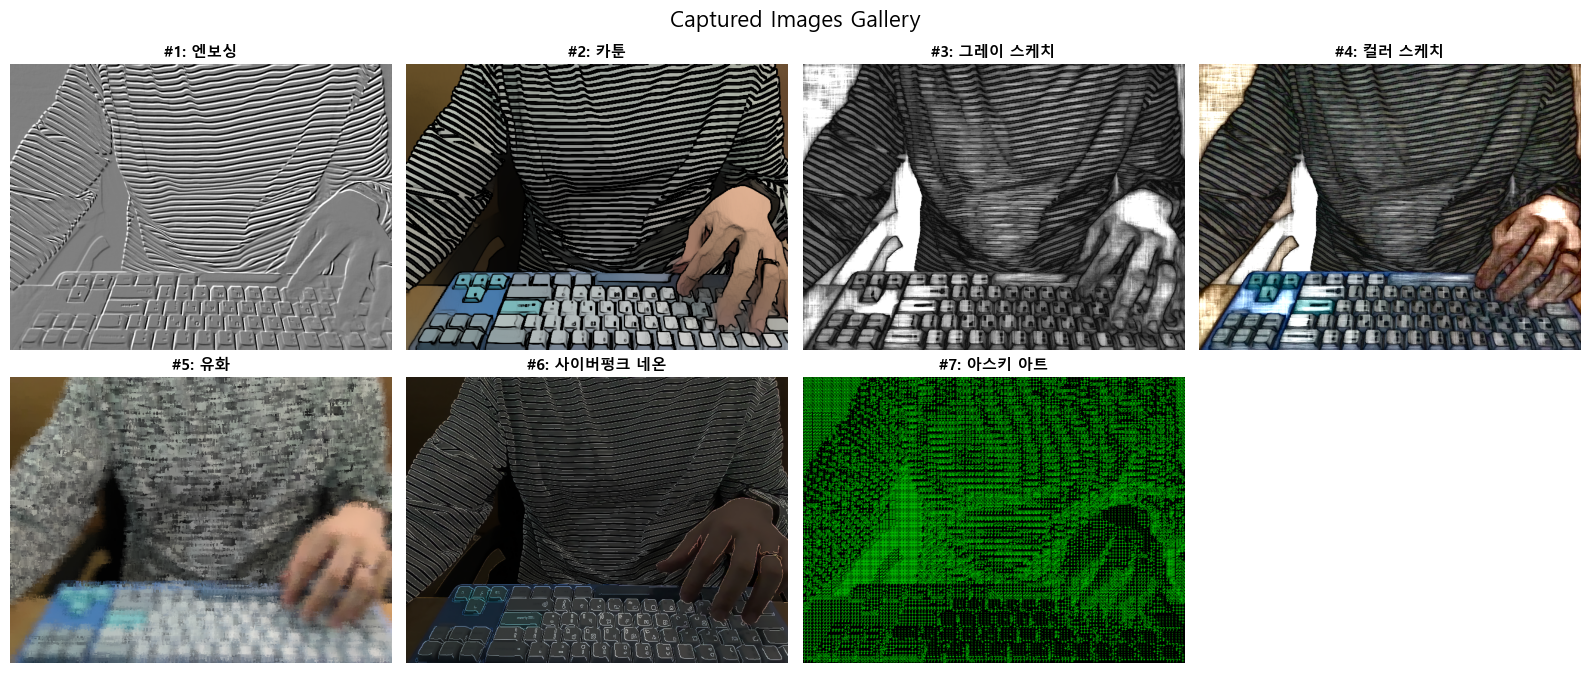

In [1]:
import sys
import cv2 as cv
import numpy as np
import winsound
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import font_manager, rc
from PyQt5.QtWidgets import QApplication, QFileDialog, QMainWindow, QPushButton, QLabel
# 한글 폰트 설정 (Windows 맑은 고딕)
font_path = "c:/Windows/fonts/malgun.ttf"
font_name = font_manager.FontProperties(fname=font_path).get_name()
matplotlib.rc('font', family=font_name)
# 필터 이름 정의
EFFECT_NAMES = {
    0: "원본",
    1: "엔보싱",
    2: "카툰",
    3: "그레이 스케치",
    4: "컬러 스케치",
    5: "유화",
    6: "사이버펑크 네온",
    7: "아스키 아트"
}

def ascii_art_filter(frame):
    small_gray = cv.resize(frame, (120, 90))
    small_gray = cv.cvtColor(small_gray, cv.COLOR_BGR2GRAY)
    
    ascii_chars = ["@", "#", "S", "%", "?", "*", "+", ";", ":", ",", "."]
    
    h, w = frame.shape[:2]
    ascii_frame = np.zeros((h, w, 3), dtype=np.uint8)
    
    cell_w, cell_h = w / 120, h / 90
    for y in range(90):
        for x in range(120):
            brightness = small_gray[y, x]
            char_idx = int((brightness / 255) * (len(ascii_chars) - 1))
            char = ascii_chars[char_idx]
            
            pos = (int(x * cell_w), int(y * cell_h) + int(cell_h))
            cv.putText(ascii_frame, char, pos, cv.FONT_HERSHEY_SIMPLEX, 0.3, (0, 255, 0), 1)
            
    return ascii_frame

def apply_effect(frame, effect_type):
    if effect_type == 1:
        femboss = np.array([[-1.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 1.0]])
        gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
        gray16 = np.int16(gray)
        emboss = np.uint8(np.clip(cv.filter2D(gray16, -1, femboss) + 128, 0, 255))
        return cv.cvtColor(emboss, cv.COLOR_GRAY2BGR)

    elif effect_type == 2:
        return cv.stylization(frame, sigma_s=60, sigma_r=0.45)

    elif effect_type == 3:
        sketch_gray, _ = cv.pencilSketch(frame, sigma_s=60, sigma_r=0.07, shade_factor=0.02)
        return cv.cvtColor(sketch_gray, cv.COLOR_GRAY2BGR)

    elif effect_type == 4:
        _, sketch_color = cv.pencilSketch(frame, sigma_s=60, sigma_r=0.07, shade_factor=0.02)
        return sketch_color

    elif effect_type == 5:
        try:
            return cv.xphoto.oilPainting(frame, 7, 1, cv.COLOR_BGR2Lab)
        except AttributeError:
            return cv.bilateralFilter(frame, 9, 75, 75)

    elif effect_type == 6:
        try:
            gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
            edges = cv.Canny(gray, 100, 200)
            neon_line = cv.cvtColor(edges, cv.COLOR_GRAY2BGR)
            neon_colored = cv.bitwise_and(frame, neon_line)
            return cv.addWeighted(frame, 0.3, neon_colored, 0.7, 0)
        except Exception as e:
            return cv.bilateralFilter(frame, 9, 75, 75)

    elif effect_type == 7:
        return ascii_art_filter(frame)

    return frame

class VideoEffectApp(QMainWindow):
    def __init__(self):
        super().__init__()
        self.setWindowTitle('실시간 영상 필터 및 캡처')
        self.setGeometry(200, 200, 550, 150)
        
        collectButton = QPushButton('영상 수집', self)
        self.showButton = QPushButton('수집 영상 보기 (Matplotlib)', self) 
        self.saveButton = QPushButton('마지막 캡처 저장', self)
        quitButton = QPushButton('나가기', self)
        self.label = QLabel('버튼을 눌러 영상 수집을 시작하세요.', self)
        
        collectButton.setGeometry(10, 25, 120, 30)
        self.showButton.setGeometry(140, 25, 170, 30) 
        self.saveButton.setGeometry(320, 25, 120, 30)
        quitButton.setGeometry(450, 25, 80, 30) 
        self.label.setGeometry(10, 70, 500, 40)

        self.showButton.setEnabled(False) 
        self.saveButton.setEnabled(False)
        
        collectButton.clicked.connect(self.collectFunction)
        self.showButton.clicked.connect(self.showFunction)       
        self.saveButton.clicked.connect(self.saveFunction)   
        quitButton.clicked.connect(self.quitFunction)        

        self.imgs = [] # (이미지 프레임, 필터 이름) 형태로 저장

    def collectFunction(self):
        self.showButton.setEnabled(False) 
        self.saveButton.setEnabled(False)
        self.label.setText('숫자키(0~7): 필터 변경 | c: 캡처 | q: 수집 종료')
        
        cap = cv.VideoCapture(0, cv.CAP_DSHOW) 
        if not cap.isOpened():
            self.label.setText('카메라 연결 실패')
            return
        
        self.imgs = []   
        current_effect = 0

        while True:
            ret, frame = cap.read()  
            if not ret: 
                break
            
            frame_resized = cv.resize(frame, (640, 480))
            output_frame = apply_effect(frame_resized, current_effect)
            
            cv.imshow('Real-time Video Effect', output_frame)
            
            key = cv.waitKey(1) & 0xFF
            
            if ord('0') <= key <= ord('7'):
                current_effect = key - ord('0')
            
            elif key == ord('c'):             
                # 이미지와 함께 현재 선택된 필터 이름을 튜플로 함께 저장
                effect_name = EFFECT_NAMES.get(current_effect, "Unknown")
                self.imgs.append((output_frame.copy(), effect_name))
                winsound.Beep(2000, 100)
            
            elif key == ord('q'):
                break 
        
        cap.release() 
        cv.destroyWindow('Real-time Video Effect') 

        if len(self.imgs) >= 1:
            self.showButton.setEnabled(True) 
            self.saveButton.setEnabled(True) 
            self.label.setText(f'총 {len(self.imgs)}장의 이미지가 캡처되었습니다.')
        else:
            self.label.setText('캡처된 이미지가 없습니다.')

    def showFunction(self):
        if not self.imgs:
            return
        
        num_imgs = len(self.imgs)
        self.label.setText(f'수집된 영상 {num_imgs}장을 Matplotlib으로 출력합니다.')
        
        cols = min(num_imgs, 4)
        rows = (num_imgs + cols - 1) // cols
        
        fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.5 * rows))
        fig.suptitle('Captured Images Gallery', fontsize=16)
        
        if num_imgs == 1:
            axes = np.array([axes])
        axes_flat = axes.flatten()
        
        for i, (img, filter_name) in enumerate(self.imgs):
            img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
            axes_flat[i].imshow(img_rgb)
            # 순번과 적용된 필터 이름을 제목으로 표시
            axes_flat[i].set_title(f'#{i+1}: {filter_name}', fontsize=11, fontweight='bold')
            axes_flat[i].axis('off')
            
        for j in range(i + 1, len(axes_flat)):
            axes_flat[j].axis('off')
            
        plt.tight_layout()
        plt.show()

    def saveFunction(self):
        if not self.imgs:
            return
        
        fname = QFileDialog.getSaveFileName(self, '파일 저장', './', 'Image Files (*.png *.jpg *.jpeg)')
        if fname[0]:
            # 저장 시 튜플의 첫 번째 요소인 이미지 데이터 사용
            last_img = self.imgs[-1][0]
            cv.imwrite(fname[0], last_img)
            self.label.setText('성공적으로 저장되었습니다.')

    def quitFunction(self): 
        cv.destroyAllWindows()  
        plt.close('all')
        self.close()

if __name__ == '__main__':
    app = QApplication(sys.argv) 
    win = VideoEffectApp() 
    win.show()
    app.exec_()

error: OpenCV(5.0.0) D:\a\opencv-python\opencv-python\opencv\modules\highgui\src\window_w32.cpp:1224: error: (-27:Null pointer) NULL window: 'Video Filter App - Before / After Split View' in function 'destroyWindowImpl'


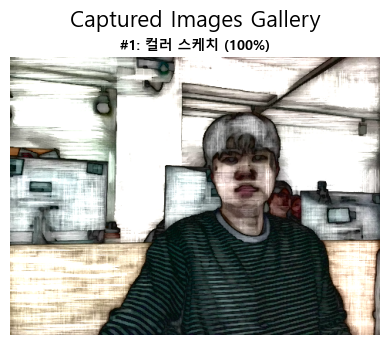

In [1]:
import sys
import os
import urllib.request
import cv2 as cv
import numpy as np
import winsound
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import font_manager, rc
from PyQt5.QtWidgets import (
    QApplication, QFileDialog, QMainWindow, QPushButton, QLabel, QSlider, QHBoxLayout, QVBoxLayout, QWidget
)
from PyQt5.QtCore import Qt

# 한글 폰트 설정 (Windows 맑은 고딕)
font_path = "c:/Windows/fonts/malgun.ttf"
if os.path.exists(font_path):
    font_name = font_manager.FontProperties(fname=font_path).get_name()
    matplotlib.rc('font', family=font_name)

# 필터 이름 재정의 (그레이 스케치 제거 및 7번 이중 필터 추가)
EFFECT_NAMES = {
    0: "원본",
    1: "엠보싱",
    2: "카툰",
    3: "컬러 스케치",
    4: "유화",
    5: "사이버펑크 네온",
    6: "아스키 아트",
    7: "이중 필터 (엠보싱+카툰)"
}

# --- 얼굴 검출 분류기(Cascade) 안전하게 로드 ---
def load_face_cascade():
    xml_name = 'haarcascade_frontalface_default.xml'
    cascade_path = cv.data.haarcascades + xml_name
    face_cascade = cv.CascadeClassifier(cascade_path)
    
    if face_cascade.empty():
        if not os.path.exists(xml_name):
            try:
                url = f"https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/{xml_name}"
                urllib.request.urlretrieve(url, xml_name)
            except Exception as e:
                print(f"XML 다운로드 실패: {e}")
        face_cascade = cv.CascadeClassifier(xml_name)
        
    return face_cascade

face_cascade = load_face_cascade()

def ascii_art_filter(frame):
    if frame.shape[0] == 0 or frame.shape[1] == 0:
        return frame
    small_gray = cv.resize(frame, (120, 90))
    if len(small_gray.shape) == 3:
        small_gray = cv.cvtColor(small_gray, cv.COLOR_BGR2GRAY)
    
    ascii_chars = ["@", "#", "S", "%", "?", "*", "+", ";", ":", ",", "."]
    
    h, w = frame.shape[:2]
    ascii_frame = np.zeros((h, w, 3), dtype=np.uint8)
    
    cell_w, cell_h = w / 120, h / 90
    for y in range(90):
        for x in range(120):
            brightness = small_gray[y, x]
            char_idx = int((brightness / 255) * (len(ascii_chars) - 1))
            char = ascii_chars[char_idx]
            
            pos = (int(x * cell_w), int(y * cell_h) + int(cell_h))
            cv.putText(ascii_frame, char, pos, cv.FONT_HERSHEY_SIMPLEX, 0.3, (0, 255, 0), 1)
            
    return ascii_frame

def apply_effect(frame, effect_type):
    """단일 및 이중 필터 연산"""
    if effect_type == 1:
        # 1. 엠보싱
        femboss = np.array([[-1.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 1.0]])
        gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
        gray16 = np.int16(gray)
        emboss = np.uint8(np.clip(cv.filter2D(gray16, -1, femboss) + 128, 0, 255))
        return cv.cvtColor(emboss, cv.COLOR_GRAY2BGR)

    elif effect_type == 2:
        # 2. 카툰
        return cv.stylization(frame, sigma_s=60, sigma_r=0.45)

    elif effect_type == 3:
        # 3. 컬러 스케치
        _, sketch_color = cv.pencilSketch(frame, sigma_s=60, sigma_r=0.07, shade_factor=0.02)
        return sketch_color

    elif effect_type == 4:
        # 4. 유화
        try:
            return cv.xphoto.oilPainting(frame, 7, 1, cv.COLOR_BGR2Lab)
        except AttributeError:
            return cv.bilateralFilter(frame, 9, 75, 75)

    elif effect_type == 5:
        # 5. 사이버펑크 네온
        try:
            gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
            edges = cv.Canny(gray, 100, 200)
            neon_line = cv.cvtColor(edges, cv.COLOR_GRAY2BGR)
            neon_colored = cv.bitwise_and(frame, neon_line)
            return cv.addWeighted(frame, 0.3, neon_colored, 0.7, 0)
        except Exception:
            return cv.bilateralFilter(frame, 9, 75, 75)

    elif effect_type == 6:
        # 6. 아스키 아트
        return ascii_art_filter(frame)

    elif effect_type == 7:
        # 7. 이중 필터 동시 적용 (1번 엠보싱 + 2번 카툰 50:50 혼합)
        emboss_img = apply_effect(frame, 1)
        cartoon_img = apply_effect(frame, 2)
        return cv.addWeighted(emboss_img, 0.5, cartoon_img, 0.5, 0)

    return frame

def apply_effect_with_intensity(frame, effect_type, intensity_ratio):
    """슬라이더 강도 값(0.0 ~ 1.0)에 맞춰 원본과 필터 결과를 합성"""
    if effect_type == 0 or intensity_ratio <= 0.0:
        return frame
    
    filtered = apply_effect(frame, effect_type)
    
    if intensity_ratio >= 1.0:
        return filtered
        
    # alpha: 필터 비율, beta: 원본 비율
    return cv.addWeighted(filtered, intensity_ratio, frame, 1.0 - intensity_ratio, 0)

def process_face_effect(frame, effect_type, intensity_ratio):
    """얼굴 인식 시 검출 영역에만 강도가 반영된 필터를 적용 및 녹색 박스 생성"""
    result_frame = frame.copy()
    
    if face_cascade.empty():
        cv.putText(result_frame, "Face Cascade XML Not Found!", (20, 50), 
                   cv.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
        return result_frame

    gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(60, 60))

    for (x, y, w, h) in faces:
        face_roi = frame[y:y+h, x:x+w]

        if effect_type != 0:
            filtered_roi = apply_effect_with_intensity(face_roi, effect_type, intensity_ratio)
            result_frame[y:y+h, x:x+w] = filtered_roi

        cv.rectangle(result_frame, (x, y), (x + w, y + h), (0, 255, 0), 2)

    return result_frame

class VideoEffectApp(QMainWindow):
    def __init__(self):
        super().__init__()
        self.setWindowTitle('실시간 영상 필터 및 캡처 (Before/After & 강도 조절)')
        self.setGeometry(200, 200, 600, 220)
        
        # 메인 레이아웃 구성
        central_widget = QWidget()
        self.setCentralWidget(central_widget)
        main_layout = QVBoxLayout(central_widget)

        # 버튼 레이아웃
        btn_layout = QHBoxLayout()
        collectButton = QPushButton('영상 수집', self)
        self.showButton = QPushButton('수집 영상 보기 (Matplotlib)', self) 
        self.saveButton = QPushButton('마지막 캡처 저장', self)
        quitButton = QPushButton('나가기', self)
        
        btn_layout.addWidget(collectButton)
        btn_layout.addWidget(self.showButton)
        btn_layout.addWidget(self.saveButton)
        btn_layout.addWidget(quitButton)

        # 슬라이더 레이아웃
        slider_layout = QHBoxLayout()
        slider_label = QLabel('필터 적용 강도: ', self)
        self.slider = QSlider(Qt.Horizontal, self)
        self.slider.setRange(0, 100)
        self.slider.setValue(100) # 기본 100%
        self.slider_val_label = QLabel('100%', self)
        
        self.slider.valueChanged.connect(self.update_slider_label)
        
        slider_layout.addWidget(slider_label)
        slider_layout.addWidget(self.slider)
        slider_layout.addWidget(self.slider_val_label)

        self.label = QLabel('버튼을 눌러 영상 수집을 시작하세요.', self)
        
        main_layout.addLayout(btn_layout)
        main_layout.addLayout(slider_layout)
        main_layout.addWidget(self.label)

        self.showButton.setEnabled(False) 
        self.saveButton.setEnabled(False)
        
        collectButton.clicked.connect(self.collectFunction)
        self.showButton.clicked.connect(self.showFunction)       
        self.saveButton.clicked.connect(self.saveFunction)   
        quitButton.clicked.connect(self.quitFunction)        

        self.imgs = []

    def update_slider_label(self, value):
        self.slider_val_label.setText(f"{value}%")

    def collectFunction(self):
        self.showButton.setEnabled(False) 
        self.saveButton.setEnabled(False)
        self.label.setText('0~7: 필터 선택 | 8: 얼굴 인식 토글 | c: 캡처 | q: 종료')
        
        cap = cv.VideoCapture(0, cv.CAP_DSHOW) 
        if not cap.isOpened():
            self.label.setText('카메라 연결 실패')
            return
        
        self.imgs = []   
        current_effect = 0
        face_mode = False

        while True:
            ret, frame = cap.read()  
            if not ret: 
                break
            
            frame_resized = cv.resize(frame, (480, 360)) # 분할 화면 출력을 고려해 개별 해상도 조절
            intensity_ratio = self.slider.value() / 100.0 # 슬라이더 값 계산 (0.0 ~ 1.0)
            
            # 필터 적용 프레임 생성
            if face_mode:
                processed_frame = process_face_effect(frame_resized, current_effect, intensity_ratio)
            else:
                processed_frame = apply_effect_with_intensity(frame_resized, current_effect, intensity_ratio)
            
            # Before / After 텍스트 표기
            before_display = frame_resized.copy()
            cv.putText(before_display, "Before (Original)", (10, 30), cv.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
            
            after_display = processed_frame.copy()
            cv.putText(after_display, "After (Filtered)", (10, 30), cv.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

            # 좌우로 결합하여 2분할 화면 구성
            split_screen = np.hstack((before_display, after_display))
            
            cv.imshow('Video Filter App - Before / After Split View', split_screen)
            
            key = cv.waitKey(1) & 0xFF
            
            # 0~7 키: 필터 선택
            if ord('0') <= key <= ord('7'):
                current_effect = key - ord('0')
            
            # 8 키: 얼굴 인식 모드 토글
            elif key == ord('8'):
                face_mode = not face_mode
                winsound.Beep(1500, 80)
            
            # c 키: 결과 이미지(After) 캡처
            elif key == ord('c'):             
                filter_base_name = EFFECT_NAMES.get(current_effect, "Unknown")
                effect_name = f"[얼굴전용] {filter_base_name}" if face_mode else filter_base_name
                effect_name += f" ({self.slider.value()}%)"
                
                # 캡처는 필터가 적용된 오른쪽 After 영상 저장을 기본으로 함
                self.imgs.append((processed_frame.copy(), effect_name))
                winsound.Beep(2000, 100)
            
            # q 키: 수집 종료
            elif key == ord('q'):
                break 
        
        cap.release() 
        cv.destroyWindow('Video Filter App - Before / After Split View') 

        if len(self.imgs) >= 1:
            self.showButton.setEnabled(True) 
            self.saveButton.setEnabled(True) 
            self.label.setText(f'총 {len(self.imgs)}장의 이미지가 캡처되었습니다.')
        else:
            self.label.setText('캡처된 이미지가 없습니다.')

    def showFunction(self):
        if not self.imgs:
            return
        
        num_imgs = len(self.imgs)
        self.label.setText(f'수집된 영상 {num_imgs}장을 Matplotlib으로 출력합니다.')
        
        cols = min(num_imgs, 4)
        rows = (num_imgs + cols - 1) // cols
        
        fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.5 * rows))
        fig.suptitle('Captured Images Gallery', fontsize=16)
        
        if num_imgs == 1:
            axes = np.array([axes])
        axes_flat = axes.flatten()
        
        for i, (img, filter_name) in enumerate(self.imgs):
            img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
            axes_flat[i].imshow(img_rgb)
            axes_flat[i].set_title(f'#{i+1}: {filter_name}', fontsize=10, fontweight='bold')
            axes_flat[i].axis('off')
            
        for j in range(i + 1, len(axes_flat)):
            axes_flat[j].axis('off')
            
        plt.tight_layout()
        plt.show()

    def saveFunction(self):
        if not self.imgs:
            return
        
        fname = QFileDialog.getSaveFileName(self, '파일 저장', './', 'Image Files (*.png *.jpg *.jpeg)')
        if fname[0]:
            last_img = self.imgs[-1][0]
            cv.imwrite(fname[0], last_img)
            self.label.setText('성공적으로 저장되었습니다.')

    def quitFunction(self): 
        cv.destroyAllWindows()  
        plt.close('all')
        self.close()

if __name__ == '__main__':
    app = QApplication(sys.argv) 
    win = VideoEffectApp() 
    win.show()
    app.exec_()

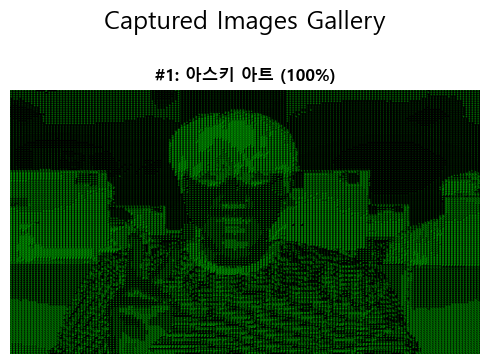

KeyboardInterrupt: 

In [ ]:
import sys
import os
import urllib.request
import cv2 as cv
import numpy as np
import winsound
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import font_manager, rc
from PyQt5.QtWidgets import (
    QApplication, QFileDialog, QMainWindow, QPushButton, QLabel, QSlider, QHBoxLayout, QVBoxLayout, QWidget
)
from PyQt5.QtCore import Qt

# 한글 폰트 설정 (Windows 맑은 고딕)
font_path = "c:/Windows/fonts/malgun.ttf"
if os.path.exists(font_path):
    font_name = font_manager.FontProperties(fname=font_path).get_name()
    matplotlib.rc('font', family=font_name)

# 필터 이름 정의
EFFECT_NAMES = {
    0: "원본",
    1: "엠보싱",
    2: "카툰",
    3: "컬러 스케치",
    4: "유화",
    5: "사이버펑크 네온",
    6: "아스키 아트",
    7: "이중 필터 (엠보싱+카툰)"
}

# --- 얼굴 검출 분류기(Cascade) 안전하게 로드 ---
def load_face_cascade():
    xml_name = 'haarcascade_frontalface_default.xml'
    cascade_path = cv.data.haarcascades + xml_name
    face_cascade = cv.CascadeClassifier(cascade_path)
    
    if face_cascade.empty():
        if not os.path.exists(xml_name):
            try:
                url = f"https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/{xml_name}"
                urllib.request.urlretrieve(url, xml_name)
            except Exception as e:
                print(f"XML 다운로드 실패: {e}")
        face_cascade = cv.CascadeClassifier(xml_name)
        
    return face_cascade

face_cascade = load_face_cascade()

def ascii_art_filter(frame):
    if frame.shape[0] == 0 or frame.shape[1] == 0:
        return frame
    # 해상도가 커짐에 따라 아스키 글자 그리드도 조절
    small_gray = cv.resize(frame, (160, 120))
    if len(small_gray.shape) == 3:
        small_gray = cv.cvtColor(small_gray, cv.COLOR_BGR2GRAY)
    
    ascii_chars = ["@", "#", "S", "%", "?", "*", "+", ";", ":", ",", "."]
    
    h, w = frame.shape[:2]
    ascii_frame = np.zeros((h, w, 3), dtype=np.uint8)
    
    cell_w, cell_h = w / 160, h / 120
    for y in range(120):
        for x in range(160):
            brightness = small_gray[y, x]
            char_idx = int((brightness / 255) * (len(ascii_chars) - 1))
            char = ascii_chars[char_idx]
            
            pos = (int(x * cell_w), int(y * cell_h) + int(cell_h))
            cv.putText(ascii_frame, char, pos, cv.FONT_HERSHEY_SIMPLEX, 0.35, (0, 255, 0), 1)
            
    return ascii_frame

def apply_effect(frame, effect_type):
    if effect_type == 1:
        femboss = np.array([[-1.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 1.0]])
        gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
        gray16 = np.int16(gray)
        emboss = np.uint8(np.clip(cv.filter2D(gray16, -1, femboss) + 128, 0, 255))
        return cv.cvtColor(emboss, cv.COLOR_GRAY2BGR)

    elif effect_type == 2:
        return cv.stylization(frame, sigma_s=60, sigma_r=0.45)

    elif effect_type == 3:
        _, sketch_color = cv.pencilSketch(frame, sigma_s=60, sigma_r=0.07, shade_factor=0.02)
        return sketch_color

    elif effect_type == 4:
        try:
            return cv.xphoto.oilPainting(frame, 7, 1, cv.COLOR_BGR2Lab)
        except AttributeError:
            return cv.bilateralFilter(frame, 9, 75, 75)

    elif effect_type == 5:
        try:
            gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
            edges = cv.Canny(gray, 100, 200)
            neon_line = cv.cvtColor(edges, cv.COLOR_GRAY2BGR)
            neon_colored = cv.bitwise_and(frame, neon_line)
            return cv.addWeighted(frame, 0.3, neon_colored, 0.7, 0)
        except Exception:
            return cv.bilateralFilter(frame, 9, 75, 75)

    elif effect_type == 6:
        return ascii_art_filter(frame)

    elif effect_type == 7:
        emboss_img = apply_effect(frame, 1)
        cartoon_img = apply_effect(frame, 2)
        return cv.addWeighted(emboss_img, 0.5, cartoon_img, 0.5, 0)

    return frame

def apply_effect_with_intensity(frame, effect_type, intensity_ratio):
    if effect_type == 0 or intensity_ratio <= 0.0:
        return frame
    
    filtered = apply_effect(frame, effect_type)
    
    if intensity_ratio >= 1.0:
        return filtered
        
    return cv.addWeighted(filtered, intensity_ratio, frame, 1.0 - intensity_ratio, 0)

def process_face_effect(frame, effect_type, intensity_ratio):
    result_frame = frame.copy()
    
    if face_cascade.empty():
        cv.putText(result_frame, "Face Cascade XML Not Found!", (30, 60), 
                   cv.FONT_HERSHEY_SIMPLEX, 1.2, (0, 0, 255), 3)
        return result_frame

    gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(100, 100))

    for (x, y, w, h) in faces:
        face_roi = frame[y:y+h, x:x+w]

        if effect_type != 0:
            filtered_roi = apply_effect_with_intensity(face_roi, effect_type, intensity_ratio)
            result_frame[y:y+h, x:x+w] = filtered_roi

        # 녹색 박스 선 두께를 4px로 키움
        cv.rectangle(result_frame, (x, y), (x + w, y + h), (0, 255, 0), 4)

    return result_frame

class VideoEffectApp(QMainWindow):
    def __init__(self):
        super().__init__()
        self.setWindowTitle('실시간 영상 필터 및 캡처')
        self.setGeometry(150, 150, 700, 250)
        
        central_widget = QWidget()
        self.setCentralWidget(central_widget)
        main_layout = QVBoxLayout(central_widget)

        btn_layout = QHBoxLayout()
        collectButton = QPushButton('영상 수집', self)
        self.showButton = QPushButton('수집 영상 보기 (Matplotlib)', self) 
        self.saveButton = QPushButton('마지막 캡처 저장', self)
        quitButton = QPushButton('나가기', self)
        
        # 버튼 폰트 및 높이 확대
        for btn in [collectButton, self.showButton, self.saveButton, quitButton]:
            btn.setStyleSheet("font-size: 14px; font-weight: bold; padding: 6px;")
        
        btn_layout.addWidget(collectButton)
        btn_layout.addWidget(self.showButton)
        btn_layout.addWidget(self.saveButton)
        btn_layout.addWidget(quitButton)

        slider_layout = QHBoxLayout()
        slider_label = QLabel('필터 적용 강도: ', self)
        slider_label.setStyleSheet("font-size: 14px; font-weight: bold;")
        
        self.slider = QSlider(Qt.Horizontal, self)
        self.slider.setRange(0, 100)
        self.slider.setValue(100)
        
        self.slider_val_label = QLabel('100%', self)
        self.slider_val_label.setStyleSheet("font-size: 14px; font-weight: bold;")
        
        self.slider.valueChanged.connect(self.update_slider_label)
        
        slider_layout.addWidget(slider_label)
        slider_layout.addWidget(self.slider)
        slider_layout.addWidget(self.slider_val_label)

        self.label = QLabel('버튼을 눌러 영상 수집을 시작하세요.', self)
        self.label.setStyleSheet("font-size: 14px; color: blue;")
        
        main_layout.addLayout(btn_layout)
        main_layout.addLayout(slider_layout)
        main_layout.addWidget(self.label)

        self.showButton.setEnabled(False) 
        self.saveButton.setEnabled(False)
        
        collectButton.clicked.connect(self.collectFunction)
        self.showButton.clicked.connect(self.showFunction)       
        self.saveButton.clicked.connect(self.saveFunction)   
        quitButton.clicked.connect(self.quitFunction)        

        self.imgs = []

    def update_slider_label(self, value):
        self.slider_val_label.setText(f"{value}%")

    def collectFunction(self):
        self.showButton.setEnabled(False) 
        self.saveButton.setEnabled(False)
        self.label.setText('0~7: 필터 | 8: 얼굴 인식 토글 | 9: Before/After 분할 토글 | c: 캡처 | q: 종료')
        
        cap = cv.VideoCapture(0, cv.CAP_DSHOW) 
        if not cap.isOpened():
            self.label.setText('카메라 연결 실패')
            return
        
        self.imgs = []   
        current_effect = 0
        face_mode = False
        split_mode = False

        while True:
            ret, frame = cap.read()  
            if not ret: 
                break
            
            # 메인 프레임을 1280x720(HD 해상도)으로 대폭 확대
            frame_resized = cv.resize(frame, (1280, 720))
            intensity_ratio = self.slider.value() / 100.0
            
            if face_mode:
                processed_frame = process_face_effect(frame_resized, current_effect, intensity_ratio)
            else:
                processed_frame = apply_effect_with_intensity(frame_resized, current_effect, intensity_ratio)
            
            if split_mode:
                # 분할 화면 시 각 영역을 640x480으로 조정
                half_before = cv.resize(frame_resized, (640, 480))
                # 텍스트 크기(scale=1.2, thickness=3) 크게 확대
                cv.putText(half_before, "Before", (20, 50), cv.FONT_HERSHEY_SIMPLEX, 1.2, (0, 255, 0), 3)
                
                half_after = cv.resize(processed_frame, (640, 480))
                cv.putText(half_after, "After", (20, 50), cv.FONT_HERSHEY_SIMPLEX, 1.2, (0, 255, 0), 3)

                display_screen = np.hstack((half_before, half_after))
            else:
                display_screen = processed_frame
                # 단일 모드일 때 텍스트 크게 표시
                filter_text = f"Effect: {EFFECT_NAMES.get(current_effect, '')}"
                if face_mode:
                    filter_text += " [FACE ONLY]"
                cv.putText(display_screen, filter_text, (30, 60), cv.FONT_HERSHEY_SIMPLEX, 1.3, (0, 255, 0), 3)
            
            cv.imshow('Video Filter App', display_screen)
            
            key = cv.waitKey(1) & 0xFF
            
            if ord('0') <= key <= ord('7'):
                current_effect = key - ord('0')
            
            elif key == ord('8'):
                face_mode = not face_mode
                winsound.Beep(1500, 80)
            
            elif key == ord('9'):
                split_mode = not split_mode
                winsound.Beep(1200, 80)
            
            elif key == ord('c'):             
                filter_base_name = EFFECT_NAMES.get(current_effect, "Unknown")
                effect_name = f"[얼굴전용] {filter_base_name}" if face_mode else filter_base_name
                effect_name += f" ({self.slider.value()}%)"
                
                self.imgs.append((processed_frame.copy(), effect_name))
                winsound.Beep(2000, 100)
            
            elif key == ord('q'):
                break 
        
        cap.release() 
        cv.destroyWindow('Video Filter App') 

        if len(self.imgs) >= 1:
            self.showButton.setEnabled(True) 
            self.saveButton.setEnabled(True) 
            self.label.setText(f'총 {len(self.imgs)}장의 이미지가 캡처되었습니다.')
        else:
            self.label.setText('캡처된 이미지가 없습니다.')

    def showFunction(self):
        if not self.imgs:
            return
        
        num_imgs = len(self.imgs)
        self.label.setText(f'수집된 영상 {num_imgs}장을 Matplotlib으로 출력합니다.')
        
        cols = min(num_imgs, 4)
        rows = (num_imgs + cols - 1) // cols
        
        fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows))
        fig.suptitle('Captured Images Gallery', fontsize=18)
        
        if num_imgs == 1:
            axes = np.array([axes])
        axes_flat = axes.flatten()
        
        for i, (img, filter_name) in enumerate(self.imgs):
            img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
            axes_flat[i].imshow(img_rgb)
            axes_flat[i].set_title(f'#{i+1}: {filter_name}', fontsize=12, fontweight='bold')
            axes_flat[i].axis('off')
            
        for j in range(i + 1, len(axes_flat)):
            axes_flat[j].axis('off')
            
        plt.tight_layout()
        plt.show()

    def saveFunction(self):
        if not self.imgs:
            return
        
        fname = QFileDialog.getSaveFileName(self, '파일 저장', './', 'Image Files (*.png *.jpg *.jpeg)')
        if fname[0]:
            last_img = self.imgs[-1][0]
            cv.imwrite(fname[0], last_img)
            self.label.setText('성공적으로 저장되었습니다.')

    def quitFunction(self): 
        cv.destroyAllWindows()  
        plt.close('all')
        self.close()

if __name__ == '__main__':
    app = QApplication(sys.argv) 
    win = VideoEffectApp() 
    win.show()
    app.exec_()